# Tugas 2 – Progress Final Project | Study Club Data Science Basic
**KSM Veterantech UPNVJ 2026 · Kabinet Genesis**

| | |
|---|---|
| Kelompok | `[16]` |
| Anggota & pembagian tugas | `[Fathir Ar'Rafi Pash (2510512075) – pengumpulan data, cleaning, merging, EDA]`, `[Ghaza Arhaburrizki Ubaidillah (2610511059) – visualisasi, rancangan bobot ICP]`, `[Muhammad Iqfal Gusdian (2610501135) – Tidak berkontribusi pada pengerjaan Tugas 2]` |
| Studi kasus | Market Prioritization UMKM untuk Klay (Skalar Solutions) |
| Cakupan Milestone 1 | Data Collection → Data Preparation → EDA → Rancangan Bobot ICP |

**Di luar cakupan Tugas 2 (dikerjakan di Final Project):** K-Means (Elbow/Silhouette), skor indeks akhir & Top 5 segmen, uji sensitivitas bobot, analisis legalitas scraping, slide presentasi akhir.

**Alur notebook:** Bagian 1 (Data Collection & Understanding) → Bagian 2 (Data Preparation & Kriteria Penggugur) → Bagian 3 (EDA & Visualisasi) → Bagian 4 (Rancangan Bobot ICP) → Keterbatasan & langkah lanjut.

In [54]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import MinMaxScaler

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110

---
# BAGIAN 1 — Data Collection & Data Understanding

### 1.1 Tabel ringkasan sumber data
Kami memakai **4 sumber data publik** (batas aturan: 2–4 sumber), semuanya di **level provinsi** dengan cakupan **38 provinsi** (> 20 unit wilayah, syarat K-Means bermakna).

In [55]:
sumber = pd.DataFrame([
 {"Kode":"S1","Nama sumber":"Laporan Basis Data Tunggal UMKM (SIDT-UMKM) per 31 Des 2025 – Kementerian UMKM",
  "Link akses":"https://bit.ly/3UoQf3O (halaman 25)",
  "Alasan dipilih":"Satu-satunya sumber resmi jumlah UMKM non-pertanian per provinsi; dasar indikator Ukuran Pasar.",
  "Level agregasi":"Provinsi (36 dari 38 provinsi tersedia)",
  "Kolom kunci":"provinsi, umkm_total (mikro+kecil+menengah)",
  "Keterbatasan":"Tidak ada pemisahan sektor (ritel/F&B/jasa) & tidak ada level kab/kota; 2 provinsi baru (Papua Barat Daya, Papua Pegunungan) tidak ada; nilai dibaca dari grafik (Gambar 7)."},
 {"Kode":"S2","Nama sumber":"BPS – Persentase Penduduk Usia 5+ yang Mengakses Internet 3 Bulan Terakhir menurut Provinsi & Klasifikasi Desa-Kota, 2024",
  "Link akses":"https://www.bps.go.id/en/statistics-table/2/NjU2IzI=/persentase-penduduk-berumur-5-tahun-ke-atas-yang-mengakses-internet-selama-tiga-bulan-terakhir-menurut-provinsi-dan-tipe-daerah-.html(tabel 'Percentage of Population 5 Years of Age and Over Who Used the Internet ...')",
  "Alasan dipilih":"Proxy resmi Kesiapan Digital (ICP Bagian 3).",
  "Level agregasi":"Provinsi (38)",
  "Kolom kunci":"provinsi, internet_urban, internet_rural, internet_total",
  "Keterbatasan":"Tahun 2024 (beda tahun dgn S1); mengukur penduduk, bukan pelaku UMKM; DKI Jakarta tidak punya nilai rural ('-'); indikator ponsel tidak ada."},
 {"Kode":"S3","Nama sumber":"BPS – PDRB Atas Dasar Harga Berlaku menurut Provinsi (miliar rupiah), 2021–2025 (Lampiran 1)",
  "Link akses":"https://www.bps.go.id/id/publication/2026/04/30/f01b7d753185ea2e879d321f/produk-domestik-regional-bruto-provinsi-provinsi-di-indonesia-menurut-pengeluaran-2021-2025.html (Data terdapat di Lampiran Appendix 41)",
  "Alasan dipilih":"Proxy Aktivitas Ekonomi (ICP Bagian 3).",
  "Level agregasi":"Provinsi (38)",
  "Kolom kunci":"provinsi, pdrb_2021 … pdrb_2025",
  "Keterbatasan":"2024* = angka sementara, 2025** = angka sangat sementara; provinsi pemekaran baru kosong utk 2021–2022; PDRB total, bukan khusus UMKM."},
 {"Kode":"S4","Nama sumber":"Databoks/Katadata – Jumlah Merchant QRIS per Provinsi, 31 Maret 2025 (sumber asli: ASPI)",
  "Link akses":"https://databoks.katadata.co.id/en/finance/statistics/689990a85da61/number-of-qris-merchants-per-province-quarter-i-2025",
  "Alasan dipilih":"Satu-satunya indikator adopsi pembayaran digital per provinsi yang terbuka (ICP: 'siap QRIS').",
  "Level agregasi":"Provinsi (34 dari 38)",
  "Kolom kunci":"provinsi, qris_merchant",
  "Keterbatasan":"Angka dibulatkan; 4 provinsi pemekaran Papua tidak ada (kemungkinan masih digabung ke Papua/Papua Barat); mencakup SEMUA merchant, bukan hanya UMKM non-pertanian; nama provinsi berbahasa Inggris."},
])
sumber.style.set_properties(**{"text-align":"left","white-space":"pre-wrap"})

,Kode,Nama sumber,Link akses,Alasan dipilih,Level agregasi,Kolom kunci,Keterbatasan
0,S1,Laporan Basis Data Tunggal UMKM (SIDT-UMKM) per 31 Des 2025 – Kementerian UMKM,https://bit.ly/3UoQf3O (halaman 25),Satu-satunya sumber resmi jumlah UMKM non-pertanian per provinsi; dasar indikator Ukuran Pasar.,Provinsi (36 dari 38 provinsi tersedia),"provinsi, umkm_total (mikro+kecil+menengah)","Tidak ada pemisahan sektor (ritel/F&B/jasa) & tidak ada level kab/kota; 2 provinsi baru (Papua Barat Daya, Papua Pegunungan) tidak ada; nilai dibaca dari grafik (Gambar 7)."
1,S2,"BPS – Persentase Penduduk Usia 5+ yang Mengakses Internet 3 Bulan Terakhir menurut Provinsi & Klasifikasi Desa-Kota, 2024",https://www.bps.go.id/en/statistics-table/2/NjU2IzI=/persentase-penduduk-berumur-5-tahun-ke-atas-yang-mengakses-internet-selama-tiga-bulan-terakhir-menurut-provinsi-dan-tipe-daerah-.html(tabel 'Percentage of Population 5 Years of Age and Over Who Used the Internet ...'),Proxy resmi Kesiapan Digital (ICP Bagian 3).,Provinsi (38),"provinsi, internet_urban, internet_rural, internet_total","Tahun 2024 (beda tahun dgn S1); mengukur penduduk, bukan pelaku UMKM; DKI Jakarta tidak punya nilai rural ('-'); indikator ponsel tidak ada."
2,S3,"BPS – PDRB Atas Dasar Harga Berlaku menurut Provinsi (miliar rupiah), 2021–2025 (Lampiran 1)",https://www.bps.go.id/id/publication/2026/04/30/f01b7d753185ea2e879d321f/produk-domestik-regional-bruto-provinsi-provinsi-di-indonesia-menurut-pengeluaran-2021-2025.html (Data terdapat di Lampiran Appendix 41),Proxy Aktivitas Ekonomi (ICP Bagian 3).,Provinsi (38),"provinsi, pdrb_2021 … pdrb_2025","2024* = angka sementara, 2025** = angka sangat sementara; provinsi pemekaran baru kosong utk 2021–2022; PDRB total, bukan khusus UMKM."
3,S4,"Databoks/Katadata – Jumlah Merchant QRIS per Provinsi, 31 Maret 2025 (sumber asli: ASPI)",https://databoks.katadata.co.id/en/finance/statistics/689990a85da61/number-of-qris-merchants-per-province-quarter-i-2025,Satu-satunya indikator adopsi pembayaran digital per provinsi yang terbuka (ICP: 'siap QRIS').,Provinsi (34 dari 38),"provinsi, qris_merchant","Angka dibulatkan; 4 provinsi pemekaran Papua tidak ada (kemungkinan masih digabung ke Papua/Papua Barat); mencakup SEMUA merchant, bukan hanya UMKM non-pertanian; nama provinsi berbahasa Inggris."


### 1.2 Memasukkan data mentah
Data ditranskripsi dari tabel/grafik sumber (tidak ada file yang perlu di-upload), sehingga notebook langsung bisa dijalankan di Colab. Nilai kosong ditulis `None` — **tidak ditebak/diisi**.

In [56]:
# ---------- S1: UMKM non-pertanian per provinsi (unit usaha), SIDT-UMKM 31 Des 2025 ----------
umkm_raw = {
 "JAWA BARAT":5429638, "JAWA TIMUR":4586514, "JAWA TENGAH":4451206, "SUMATERA UTARA":1485080,
 "DKI JAKARTA":1337401, "BANTEN":1174765, "SULAWESI SELATAN":1087977, "LAMPUNG":903922,
 "SUMATERA SELATAN":897769, "SUMATERA BARAT":740347, "NUSA TENGGARA BARAT":649494, "BALI":642259,
 "ACEH":624542, "NUSA TENGGARA TIMUR":607663, "RIAU":580624, "DI YOGYAKARTA":572297,
 "KALIMANTAN SELATAN":518542, "SULAWESI UTARA":382211, "JAMBI":344836, "KALIMANTAN BARAT":338258,
 "SULAWESI TENGAH":324166, "SULAWESI TENGGARA":312782, "KALIMANTAN TIMUR":293525, "KALIMANTAN TENGAH":283940,
 "BENGKULU":274900, "GORONTALO":216940, "KEP. BANGKA BELITUNG":210303, "KEP. RIAU":201974,
 "SULAWESI BARAT":189055, "MALUKU":182233, "MALUKU UTARA":134398, "PAPUA BARAT":82369,
 "PAPUA":64761, "KALIMANTAN UTARA":51840, "PAPUA TENGAH":17257, "PAPUA SELATAN":13281,
}
df_umkm = pd.DataFrame(list(umkm_raw.items()), columns=["provinsi","umkm_total"])

# ---------- S2: Internet (% penduduk 5+ th, 2024): urban, rural, urban+rural ----------
net_rows = [
 ("ACEH",70.80,58.66,62.93),("SUMATERA UTARA",77.43,69.69,74.15),("SUMATERA BARAT",79.16,69.78,74.59),
 ("RIAU",84.30,73.20,77.68),("JAMBI",78.17,68.55,71.76),("SUMATERA SELATAN",80.34,64.50,70.54),
 ("BENGKULU",81.96,65.01,70.72),("LAMPUNG",77.24,71.37,73.37),("KEP. BANGKA BELITUNG",80.08,70.41,76.06),
 ("KEP. RIAU",91.52,69.66,89.26),("DKI JAKARTA",87.84,None,87.84),("JAWA BARAT",79.42,65.35,76.62),
 ("JAWA TENGAH",76.08,69.78,73.15),("DI YOGYAKARTA",83.98,68.24,80.10),("JAWA TIMUR",75.22,61.69,69.36),
 ("BANTEN",79.82,56.77,75.17),("BALI",81.73,66.39,77.56),("NUSA TENGGARA BARAT",72.88,63.76,68.52),
 ("NUSA TENGGARA TIMUR",76.88,46.73,54.84),("KALIMANTAN BARAT",83.78,64.02,71.57),("KALIMANTAN TENGAH",84.29,68.19,75.23),
 ("KALIMANTAN SELATAN",80.63,68.96,74.82),("KALIMANTAN TIMUR",87.33,77.91,84.44),("KALIMANTAN UTARA",81.92,69.24,77.44),
 ("SULAWESI UTARA",75.08,60.13,68.44),("SULAWESI TENGAH",75.99,55.70,62.44),("SULAWESI SELATAN",78.63,62.43,70.10),
 ("SULAWESI TENGGARA",78.79,64.96,70.36),("GORONTALO",74.03,59.04,65.92),("SULAWESI BARAT",77.28,63.90,66.61),
 ("MALUKU",74.74,48.44,59.96),("MALUKU UTARA",80.10,50.46,59.17),("PAPUA BARAT",79.14,55.75,62.96),
 ("PAPUA BARAT DAYA",77.98,53.40,65.75),("PAPUA",77.56,39.32,62.24),("PAPUA SELATAN",74.09,33.58,48.44),
 ("PAPUA TENGAH",82.62,12.30,28.71),("PAPUA PEGUNUNGAN",41.86,4.15,6.76),
]
df_net = pd.DataFrame(net_rows, columns=["provinsi","internet_urban","internet_rural","internet_total"])
internet_nasional = {"urban":79.13, "rural":63.71, "total":72.78}   # baris INDONESIA (untuk validasi)

# ---------- S3: PDRB ADHB (miliar rupiah) 2021-2025 ----------
N = np.nan
pdrb_rows = [
 ("Aceh",184979.88,209698.36,227018.29,243202.15,257502.43),
 ("Sumatera Utara",859934.26,955193.09,1050995.41,1146919.75,1236193.57),
 ("Sumatera Barat",253100.20,285375.36,312811.02,333145.84,352189.40),
 ("Riau",839002.41,991615.38,1026472.05,1112481.62,1201383.76),
 ("Jambi",232294.15,276936.85,293867.57,323174.33,349662.60),
 ("Sumatera Selatan",493636.85,590079.43,629168.67,663961.72,720205.22),
 ("Bengkulu",79602.64,90111.95,96583.15,103991.93,111829.42),
 ("Lampung",371198.88,414119.68,448819.04,484042.52,523846.54),
 ("Kepulauan Bangka Belitung",85961.29,95286.44,102526.32,107503.18,116811.75),
 ("Kepulauan Riau",275622.85,308739.72,331644.52,352436.43,381729.88),
 ("DKI Jakarta",2912885.34,3188541.22,3443359.21,3679708.72,3926153.30),
 ("Jawa Barat",2204660.23,2422782.32,2625198.63,2823451.79,3038667.95),
 ("Jawa Tengah",1419735.15,1559140.36,1695427.92,1817710.82,1943187.66),
 ("DI Yogyakarta",149413.65,165724.53,180746.37,193561.94,208133.80),
 ("Jawa Timur",2454792.00,2731423.63,2953546.98,3168295.58,3403166.85),
 ("Banten",665870.30,747220.84,814122.03,873626.25,936203.98),
 ("Bali",220466.43,245367.89,274382.04,298439.56,324148.94),
 ("Nusa Tenggara Barat",140115.27,156942.67,166395.45,182265.62,192951.54),
 ("Nusa Tenggara Timur",110881.41,118722.45,128525.78,137458.48,148373.38),
 ("Kalimantan Barat",231321.16,255797.28,274468.58,300166.89,328569.51),
 ("Kalimantan Tengah",169655.94,199741.29,208783.35,222864.50,241055.70),
 ("Kalimantan Selatan",197882.42,251098.65,269192.02,286840.06,305126.93),
 ("Kalimantan Timur",696632.67,921450.99,843737.89,858193.71,889072.55),
 ("Kalimantan Utara",111530.22,138674.96,147307.72,146976.70,156025.74),
 ("Sulawesi Utara",142620.42,157039.46,171969.42,187374.29,204747.14),
 ("Sulawesi Tengah",247280.35,323630.28,347139.01,376950.32,415477.22),
 ("Sulawesi Selatan",544857.14,605175.94,652648.09,696252.76,753077.16),
 ("Sulawesi Tenggara",139476.77,158800.27,176179.90,189481.75,204333.57),
 ("Gorontalo",43893.26,47566.29,51366.74,54559.65,58977.51),
 ("Sulawesi Barat",50565.53,54028.35,58571.82,64214.65,71162.44),
 ("Maluku",48893.68,54078.63,58487.79,62647.51,66313.12),
 ("Maluku Utara",52480.52,70902.61,85938.16,96949.45,133620.32),
 ("Papua Barat",85078.49,91302.02,61576.37,76177.48,81807.57),
 ("Papua Barat Daya",N,N,36104.57,37040.34,39219.64),
 ("Papua",235487.47,262519.79,81731.73,85914.33,90513.18),
 ("Papua Selatan",N,N,31306.45,33403.64,35687.86),
 ("Papua Tengah",N,N,150377.18,174942.95,160519.15),
 ("Papua Pegunungan",N,N,24433.99,26561.43,28377.77),
]
df_pdrb = pd.DataFrame(pdrb_rows, columns=["provinsi","pdrb_2021","pdrb_2022","pdrb_2023","pdrb_2024","pdrb_2025"])
pdrb_total_38_2025 = 23636026.07   # baris 'Jumlah 38 Provinsi' (untuk validasi)

# ---------- S4: Merchant QRIS per provinsi (31 Maret 2025, ASPI via Databoks) ----------
qris_raw = {
 "West Java":8_240_000,"Jakarta":6_040_000,"East Java":4_510_000,"Central Java":3_870_000,"Banten":2_240_000,
 "North Sumatra":1_450_000,"South Sulawesi":1_170_000,"South Sumatra":979_000,"Bali":959_000,"Yogyakarta":908_000,
 "Riau":809_000,"Lampung":658_000,"East Kalimantan":644_000,"Riau Islands":606_000,"West Sumatra":597_000,
 "South Kalimantan":485_000,"West Kalimantan":418_000,"Jambi":384_000,"West Nusa Tenggara":363_000,
 "Central Kalimantan":336_000,"North Sulawesi":320_000,"East Nusa Tenggara":271_000,"Central Sulawesi":236_000,
 "Papua":230_000,"Bengkulu":197_000,"Aceh":196_000,"Southeast Sulawesi":189_000,"Bangka Belitung Islands":181_000,
 "Gorontalo":131_000,"North Maluku":112_000,"North Kalimantan":102_000,"West Papua":102_000,
 "Maluku":90_000,"West Sulawesi":87_000,
}
df_qris = pd.DataFrame(list(qris_raw.items()), columns=["provinsi","qris_merchant"])
qris_nasional = 38_000_000   # ~38 juta merchant (teks artikel, untuk validasi)

### 1.3 Memahami struktur tiap dataset (`shape`, `info`, `head`, `describe`)

In [57]:
for nama, d in [("S1 UMKM", df_umkm), ("S2 Internet", df_net), ("S3 PDRB", df_pdrb), ("S4 QRIS", df_qris)]:
    print(f"=== {nama} | shape = {d.shape} | missing total = {int(d.isna().sum().sum())} ===")
    display(d.head(3))
    print()

=== S1 UMKM | shape = (36, 2) | missing total = 0 ===


,provinsi,umkm_total
0,JAWA BARAT,5429638
1,JAWA TIMUR,4586514
2,JAWA TENGAH,4451206



=== S2 Internet | shape = (38, 4) | missing total = 1 ===


,provinsi,internet_urban,internet_rural,internet_total
0,ACEH,70.80,58.66,62.93
1,SUMATERA UTARA,77.43,69.69,74.15
2,SUMATERA BARAT,79.16,69.78,74.59



=== S3 PDRB | shape = (38, 6) | missing total = 8 ===


,provinsi,pdrb_2021,pdrb_2022,pdrb_2023,pdrb_2024,pdrb_2025
0,Aceh,"184,979.88","209,698.36","227,018.29","243,202.15","257,502.43"
1,Sumatera Utara,"859,934.26","955,193.09","1,050,995.41","1,146,919.75","1,236,193.57"
2,Sumatera Barat,"253,100.20","285,375.36","312,811.02","333,145.84","352,189.40"



=== S4 QRIS | shape = (34, 2) | missing total = 0 ===


,provinsi,qris_merchant
0,West Java,8240000
1,Jakarta,6040000
2,East Java,4510000


In [58]:
display(df_umkm.describe().T)
display(df_net.describe().T)
display(df_pdrb.describe().T)
display(df_qris.describe().T)

,count,mean,std,min,25%,50%,75%,max
umkm_total,36.00,"839,140.81","1,279,450.76","13,281.00","208,220.75","363,523.50","779,702.50","5,429,638.00"


,count,mean,std,min,25%,50%,75%,max
internet_urban,38.00,78.44,7.46,41.86,76.28,78.97,81.87,91.52
internet_rural,37.00,59.23,15.52,4.15,55.75,64.02,68.96,77.91
internet_total,38.00,68.04,14.83,6.76,63.66,70.63,75.22,89.26


,count,mean,std,min,25%,50%,75%,max
pdrb_2021,34.00,"498,582.62","710,048.44","43,893.26","118,516.86","225,893.79","532,052.07","2,912,885.34"
pdrb_2022,34.00,"563,083.21","782,590.84","47,566.29","143,241.89","253,447.96","601,401.81","3,188,541.22"
pdrb_2023,38.00,"540,340.30","818,246.05","24,433.99","98,068.94","217,900.82","584,081.26","3,443,359.21"
pdrb_2024,38.00,"579,549.75","876,534.63","26,561.43","104,869.74","233,033.33","618,981.92","3,679,708.72"
pdrb_2025,38.00,"622,000.69","938,799.22","28,377.77","121,013.89","249,279.07","671,115.55","3,926,153.30"


,count,mean,std,min,25%,50%,75%,max
qris_merchant,34.00,"1,120,882.35","1,839,756.09","87,000.00","196,250.00","401,000.00","946,250.00","8,240,000.00"


**Temuan awal Data Understanding**
- Jumlah provinsi per sumber **tidak sama**: S1 = 36, S2 = 38, S3 = 38, S4 = 34 → saat digabung akan ada nilai kosong yang harus ditangani secara eksplisit (Bagian 2).
- Penulisan nama provinsi **tidak seragam** antar sumber (HURUF BESAR / Title Case / Bahasa Inggris) → perlu standardisasi sebelum merge.
- Semua sumber berada di **level provinsi** → tidak ada masalah beda hierarki (provinsi vs kab/kota) pada dataset kami, tetapi ini menjadi **keterbatasan** terhadap anjuran level kab/kota di brief.
- Tidak ada sumber yang memuat **pemisahan sektor** (ritel/F&B/jasa) → indikator "Kepadatan Sektor Target" memakai proxy (dijelaskan di Bagian 4).

---
# BAGIAN 2 — Data Preparation & Kriteria Penggugur

## 2.1 Pembersihan data

### a) Inkonsistensi format nama wilayah
Sebelum distandardisasi, kita lihat dulu nama yang tidak cocok antar sumber.

In [59]:
# Standardisasi nama -> kunci kanonik (HURUF BESAR, singkatan 'KEP.' seperti BPS)
def std_name(s):
    s = " ".join(str(s).upper().split())
    return s.replace("KEPULAUAN ", "KEP. ")

# Terjemahan nama Inggris (S4) -> Indonesia
EN2ID = {
 "West Java":"JAWA BARAT","Jakarta":"DKI JAKARTA","East Java":"JAWA TIMUR","Central Java":"JAWA TENGAH","Banten":"BANTEN",
 "North Sumatra":"SUMATERA UTARA","South Sulawesi":"SULAWESI SELATAN","South Sumatra":"SUMATERA SELATAN","Bali":"BALI",
 "Yogyakarta":"DI YOGYAKARTA","Riau":"RIAU","Lampung":"LAMPUNG","East Kalimantan":"KALIMANTAN TIMUR","Riau Islands":"KEP. RIAU",
 "West Sumatra":"SUMATERA BARAT","South Kalimantan":"KALIMANTAN SELATAN","West Kalimantan":"KALIMANTAN BARAT","Jambi":"JAMBI",
 "West Nusa Tenggara":"NUSA TENGGARA BARAT","Central Kalimantan":"KALIMANTAN TENGAH","North Sulawesi":"SULAWESI UTARA",
 "East Nusa Tenggara":"NUSA TENGGARA TIMUR","Central Sulawesi":"SULAWESI TENGAH","Papua":"PAPUA","Bengkulu":"BENGKULU",
 "Aceh":"ACEH","Southeast Sulawesi":"SULAWESI TENGGARA","Bangka Belitung Islands":"KEP. BANGKA BELITUNG","Gorontalo":"GORONTALO",
 "North Maluku":"MALUKU UTARA","North Kalimantan":"KALIMANTAN UTARA","West Papua":"PAPUA BARAT","Maluku":"MALUKU","West Sulawesi":"SULAWESI BARAT",
}

# --- sebelum standardisasi: berapa nama S3 & S4 yang tidak ketemu di S2 (acuan 38 provinsi)? ---
acuan = set(df_net["provinsi"])
print("SEBELUM standardisasi")
print("  S3 PDRB tidak cocok :", sorted(set(df_pdrb["provinsi"]) - acuan)[:5], "... total", len(set(df_pdrb["provinsi"]) - acuan))
print("  S4 QRIS tidak cocok :", len(set(df_qris["provinsi"]) - acuan), "dari", df_qris.shape[0])

df_pdrb["provinsi"] = df_pdrb["provinsi"].map(std_name)
df_qris["provinsi"] = df_qris["provinsi"].map(EN2ID)
for d in (df_umkm, df_net):
    d["provinsi"] = d["provinsi"].map(std_name)

print("\nSESUDAH standardisasi")
print("  S1 UMKM tidak cocok :", sorted(set(df_umkm["provinsi"]) - acuan))
print("  S3 PDRB tidak cocok :", sorted(set(df_pdrb["provinsi"]) - acuan))
print("  S4 QRIS tidak cocok :", sorted(set(df_qris["provinsi"]) - acuan))
assert df_qris["provinsi"].notna().all(), "Ada nama Inggris yang belum terpetakan"

SEBELUM standardisasi
  S3 PDRB tidak cocok : ['Aceh', 'Bali', 'Banten', 'Bengkulu', 'DI Yogyakarta'] ... total 38
  S4 QRIS tidak cocok : 34 dari 34

SESUDAH standardisasi
  S1 UMKM tidak cocok : []
  S3 PDRB tidak cocok : []
  S4 QRIS tidak cocok : []


### b) Duplikat, nilai mustahil, dan validasi total terhadap sumber

In [60]:
# Duplikat
for nama, d in [("UMKM", df_umkm), ("Internet", df_net), ("PDRB", df_pdrb), ("QRIS", df_qris)]:
    print(f"Duplikat provinsi di {nama}: {d['provinsi'].duplicated().sum()}")

# Nilai mustahil (persentase 0-100, nilai positif)
assert df_net[["internet_urban","internet_rural","internet_total"]].stack().dropna().between(0,100).all()
assert (df_umkm["umkm_total"] > 0).all() and (df_qris["qris_merchant"] > 0).all()
assert (df_pdrb.drop(columns="provinsi").stack().dropna() > 0).all()
print("Rentang nilai: OK")

# Validasi silang terhadap total yang tertulis di sumber
sum_pdrb = df_pdrb["pdrb_2025"].sum()
print(f"\nSum PDRB 2025 (38 prov) = {sum_pdrb:,.2f}  vs  total sumber = {pdrb_total_38_2025:,.2f}  -> selisih {sum_pdrb-pdrb_total_38_2025:,.2f}")
assert abs(sum_pdrb - pdrb_total_38_2025) < 1.0, "Transkripsi PDRB tidak cocok dengan total!"

sum_qris = df_qris["qris_merchant"].sum()
print(f"Sum QRIS (34 prov) = {sum_qris:,.0f}  vs ~{qris_nasional:,.0f} (selisih {abs(sum_qris/qris_nasional-1):.2%})")
assert abs(sum_qris/qris_nasional - 1) < 0.02

print(f"Sum UMKM (36 prov) = {df_umkm['umkm_total'].sum():,.0f}")

Duplikat provinsi di UMKM: 0
Duplikat provinsi di Internet: 0
Duplikat provinsi di PDRB: 0
Duplikat provinsi di QRIS: 0
Rentang nilai: OK

Sum PDRB 2025 (38 prov) = 23,636,026.05  vs  total sumber = 23,636,026.07  -> selisih -0.02
Sum QRIS (34 prov) = 38,110,000  vs ~38,000,000 (selisih 0.29%)
Sum UMKM (36 prov) = 30,209,069


### c) Missing values
Aturan kami: **nilai kosong tidak diisi dengan tebakan/imputasi** (sesuai ICP Bagian 4). Hanya satu kekosongan yang bersifat *struktural* dan tidak mempengaruhi analisis utama: `internet_rural` DKI Jakarta ('-', karena Jakarta tidak punya klasifikasi desa) — kolom utama yang dipakai adalah `internet_total`, sehingga tidak perlu diisi.

## 2.2 Penggabungan data (merging) antar dataset

In [61]:
# Tabel induk 38 provinsi: kode BPS + kelompok pulau (pengelompokan BPS seperti pada tabel PDRB)
master = pd.DataFrame([
 (11,"ACEH","Sumatera"),(12,"SUMATERA UTARA","Sumatera"),(13,"SUMATERA BARAT","Sumatera"),(14,"RIAU","Sumatera"),
 (15,"JAMBI","Sumatera"),(16,"SUMATERA SELATAN","Sumatera"),(17,"BENGKULU","Sumatera"),(18,"LAMPUNG","Sumatera"),
 (19,"KEP. BANGKA BELITUNG","Sumatera"),(21,"KEP. RIAU","Sumatera"),
 (31,"DKI JAKARTA","Jawa"),(32,"JAWA BARAT","Jawa"),(33,"JAWA TENGAH","Jawa"),(34,"DI YOGYAKARTA","Jawa"),
 (35,"JAWA TIMUR","Jawa"),(36,"BANTEN","Jawa"),
 (51,"BALI","Bali-Nusra"),(52,"NUSA TENGGARA BARAT","Bali-Nusra"),(53,"NUSA TENGGARA TIMUR","Bali-Nusra"),
 (61,"KALIMANTAN BARAT","Kalimantan"),(62,"KALIMANTAN TENGAH","Kalimantan"),(63,"KALIMANTAN SELATAN","Kalimantan"),
 (64,"KALIMANTAN TIMUR","Kalimantan"),(65,"KALIMANTAN UTARA","Kalimantan"),
 (71,"SULAWESI UTARA","Sulawesi"),(72,"SULAWESI TENGAH","Sulawesi"),(73,"SULAWESI SELATAN","Sulawesi"),
 (74,"SULAWESI TENGGARA","Sulawesi"),(75,"GORONTALO","Sulawesi"),(76,"SULAWESI BARAT","Sulawesi"),
 (81,"MALUKU","Maluku-Papua"),(82,"MALUKU UTARA","Maluku-Papua"),(91,"PAPUA BARAT","Maluku-Papua"),
 (92,"PAPUA BARAT DAYA","Maluku-Papua"),(94,"PAPUA","Maluku-Papua"),(95,"PAPUA SELATAN","Maluku-Papua"),
 (96,"PAPUA TENGAH","Maluku-Papua"),(97,"PAPUA PEGUNUNGAN","Maluku-Papua"),
], columns=["kode_bps","provinsi","pulau"])
assert master.shape[0] == 38 and master["provinsi"].is_unique

# LEFT JOIN dari tabel induk -> tidak ada provinsi yang hilang diam-diam; validate memastikan kunci unik (one_to_one)
df = master.copy()
for nama, d in [("UMKM", df_umkm), ("Internet", df_net), ("PDRB", df_pdrb), ("QRIS", df_qris)]:
    n0 = df.shape[0]
    df = df.merge(d, on="provinsi", how="left", validate="one_to_one")
    assert df.shape[0] == n0, f"Jumlah baris berubah setelah merge {nama}!"
    print(f"merge {nama:9s}: baris tetap {df.shape[0]} | kolom {df.shape[1]}")

df["pdrb"] = df["pdrb_2025"]       # PDRB acuan = 2025 (tahun terdekat dgn UMKM 2025 & QRIS Q1-2025)
print("\nMissing per kolom kunci:")
display(df[["umkm_total","internet_total","pdrb","qris_merchant"]].isna().sum().to_frame("jumlah_kosong").T)

merge UMKM     : baris tetap 38 | kolom 4
merge Internet : baris tetap 38 | kolom 7
merge PDRB     : baris tetap 38 | kolom 12
merge QRIS     : baris tetap 38 | kolom 13

Missing per kolom kunci:


,umkm_total,internet_total,pdrb,qris_merchant
jumlah_kosong,2,0,0,4


**Metode penggabungan.** Seluruh sumber berada pada level yang sama (provinsi), sehingga digabung dengan *left join* pada kunci nama provinsi yang sudah distandardisasi (kolom `kode_bps` disediakan sebagai kunci cadangan / siap diperluas ke level kab/kota). Jika kelak data UMKM kab/kota tersedia, caranya: **agregasi ke provinsi** atau **broadcast** indikator level provinsi (internet, PDRB, QRIS) ke semua kab/kota di provinsi yang sama lewat 2 digit pertama kode BPS.

**Catatan penting.** Merchant QRIS "Papua" (230 ribu) dan "Papua Barat" (102 ribu) dari ASPI kemungkinan masih mencakup provinsi pemekaran (Papua Tengah/Selatan/Pegunungan dan Papua Barat Daya) — sedangkan UMKM & PDRB sudah memisahkannya. Ini **tidak kami "perbaiki"** dengan tebakan, tetapi dicatat sebagai keterbatasan.

## 2.3 Kriteria penggugur (Disqualification Filter)
Mengacu pada ICP Bagian 4:

| # | Aturan | Batas kami | Alasan |
|---|---|---|---|
| 1 | Data kunci kosong (UMKM, internet, PDRB, atau QRIS) | tidak boleh kosong | Tidak boleh ditebak; skor tidak bisa dihitung adil |
| 2 | Jumlah UMKM terlalu kecil | **< 50.000 unit usaha** | Di bawah ini pool leads sangat kecil (< 1% dari provinsi terbesar) sehingga segmen tidak bermakna untuk sales |
| 3 | Sektor tanpa transaksi harian rutin | – | **Tidak dapat diterapkan**: dataset tidak punya dimensi sektor (dicatat sebagai keterbatasan) |

In [62]:
UMKM_MIN = 50_000
KEY_COLS = {"umkm_total":"UMKM","internet_total":"Internet","pdrb":"PDRB","qris_merchant":"QRIS"}

alasan = {}
for i, r in df.iterrows():
    a = []
    kosong = [lbl for c, lbl in KEY_COLS.items() if pd.isna(r[c])]
    if kosong:
        a.append("Data kunci kosong: " + ", ".join(kosong))
    if pd.notna(r["umkm_total"]) and r["umkm_total"] < UMKM_MIN:
        a.append(f"UMKM {r['umkm_total']:,.0f} < ambang {UMKM_MIN:,}")
    if a:
        alasan[r["provinsi"]] = "; ".join(a)

df_elim = (df[df["provinsi"].isin(alasan)][["kode_bps","provinsi","pulau","umkm_total","internet_total","pdrb","qris_merchant"]]
           .assign(alasan_eliminasi=lambda x: x["provinsi"].map(alasan)))
print(f"Provinsi tereliminasi: {len(df_elim)} dari {len(df)}")
display(df_elim.style.format({"umkm_total":"{:,.0f}","qris_merchant":"{:,.0f}","pdrb":"{:,.0f}"}, na_rep="KOSONG"))

df_ok = df[~df["provinsi"].isin(alasan)].copy().reset_index(drop=True)
print(f"Provinsi lolos filter (masuk analisis): {len(df_ok)}")

Provinsi tereliminasi: 4 dari 38


,kode_bps,provinsi,pulau,umkm_total,internet_total,pdrb,qris_merchant,alasan_eliminasi
33,92,PAPUA BARAT DAYA,Maluku-Papua,KOSONG,65.750000,"39,220",KOSONG,"Data kunci kosong: UMKM, QRIS"
35,95,PAPUA SELATAN,Maluku-Papua,"13,281",48.440000,"35,688",KOSONG,"Data kunci kosong: QRIS; UMKM 13,281 < ambang 50,000"
36,96,PAPUA TENGAH,Maluku-Papua,"17,257",28.710000,"160,519",KOSONG,"Data kunci kosong: QRIS; UMKM 17,257 < ambang 50,000"
37,97,PAPUA PEGUNUNGAN,Maluku-Papua,KOSONG,6.760000,"28,378",KOSONG,"Data kunci kosong: UMKM, QRIS"


Provinsi lolos filter (masuk analisis): 34


**Catatan hasil filter.** Papua Pegunungan juga memiliki angka internet ekstrem (6,76%) — wajar bagi wilayah itu, tetapi sudah tereliminasi karena data UMKM dan QRIS kosong. Kaltara (51.840 UMKM) lolos tipis; dalam Uji Sensitivitas di Final Project, ambang 50.000 bisa digeser untuk melihat dampaknya.

## 2.4 Rekayasa fitur & penyamaan skala (normalisasi)

**Fitur turunan**
- `umkm_per_pdrb_T` = jumlah UMKM per Rp1 triliun PDRB → *proxy* kepadatan UMKM terhadap ekonomi (pengganti "kepadatan sektor target").
- `qris_per_umkm` = merchant QRIS / UMKM → rasio adopsi (hanya untuk EDA; **> 1 mungkin karena QRIS mencakup semua merchant**, bukan hanya UMKM non-pertanian).
- `gap_internet` = internet urban − rural → ukuran ketimpangan digital.

**Normalisasi:** variabel *count* (UMKM, QRIS, PDRB) sangat **miring ke kanan** (Jawa mendominasi), sehingga Min-Max langsung akan menekan hampir semua provinsi mendekati 0. Karena itu kami terapkan **`log1p` → Min-Max (0–1)**; persentase internet langsung di-Min-Max. Semua arah pengaruh = **positif** (makin tinggi makin baik).

In [63]:
df_ok["umkm_per_pdrb_T"] = df_ok["umkm_total"] / (df_ok["pdrb"] / 1000)      # pdrb miliar -> triliun
df_ok["qris_per_umkm"]   = df_ok["qris_merchant"] / df_ok["umkm_total"]
df_ok["gap_internet"]    = df_ok["internet_urban"] - df_ok["internet_rural"]  # DKI = NaN (tidak diisi)

# Cek kemiringan sebelum & sesudah log
skew = pd.DataFrame({
    "skew_raw": df_ok[["umkm_total","qris_merchant","pdrb","internet_total","umkm_per_pdrb_T"]].skew(),
    "skew_log": np.log1p(df_ok[["umkm_total","qris_merchant","pdrb","internet_total","umkm_per_pdrb_T"]]).skew(),
})
display(skew)

# Transformasi + Min-Max
X = pd.DataFrame({
    "umkm_total":       np.log1p(df_ok["umkm_total"]),
    "umkm_per_pdrb_T":  df_ok["umkm_per_pdrb_T"],
    "internet_total":   df_ok["internet_total"],
    "qris_merchant":    np.log1p(df_ok["qris_merchant"]),
    "pdrb":             np.log1p(df_ok["pdrb"]),
})
scaler = MinMaxScaler()
df_norm = pd.DataFrame(scaler.fit_transform(X), columns=[c + "_n" for c in X.columns])
df_norm.insert(0, "provinsi", df_ok["provinsi"])

# Validasi normalisasi
assert np.allclose(df_norm.drop(columns="provinsi").min(), 0) and np.allclose(df_norm.drop(columns="provinsi").max(), 1)
assert df_norm.drop(columns="provinsi").notna().all().all()
display(df_norm.describe().T[["min","max","mean"]])
display(df_norm.head())

,skew_raw,skew_log
umkm_total,2.70,0.34
qris_merchant,2.72,0.65
pdrb,2.32,0.53
internet_total,0.12,-0.20
umkm_per_pdrb_T,0.73,-0.62


,min,max,mean
umkm_total_n,0.00,1.00,0.47
umkm_per_pdrb_T_n,0.00,1.00,0.35
internet_total_n,0.00,1.00,0.49
qris_merchant_n,0.00,1.00,0.38
pdrb_n,0.00,1.00,0.42


,provinsi,umkm_total_n,umkm_per_pdrb_T_n,internet_total_n,qris_merchant_n,pdrb_n
0,ACEH,0.54,0.56,0.24,0.18,0.35
1,SUMATERA UTARA,0.72,0.23,0.56,0.62,0.72
2,SUMATERA BARAT,0.57,0.47,0.57,0.42,0.43
3,RIAU,0.52,0.04,0.66,0.49,0.72
4,JAMBI,0.41,0.17,0.49,0.33,0.42


**Validasi akhir data bersih** – jumlah baris, tipe, tidak ada nilai kosong pada kolom kunci.

In [64]:
print("Shape df_ok :", df_ok.shape, "| provinsi unik:", df_ok["provinsi"].nunique())
print("Kosong di kolom kunci:", int(df_ok[list(KEY_COLS)].isna().sum().sum()))
df_ok.info()
# Simpan agar bisa dipakai di Final Project (opsional, file muncul di panel kiri Colab)
df_ok.to_csv("data_bersih_provinsi.csv", index=False)
df_norm.to_csv("data_ternormalisasi_provinsi.csv", index=False)

Shape df_ok : (34, 17) | provinsi unik: 34
Kosong di kolom kunci: 0
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 34 entries, 0 to 33
Data columns (total 17 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   kode_bps         34 non-null     int64  
 1   provinsi         34 non-null     object 
 2   pulau            34 non-null     object 
 3   umkm_total       34 non-null     float64
 4   internet_urban   34 non-null     float64
 5   internet_rural   33 non-null     float64
 6   internet_total   34 non-null     float64
 7   pdrb_2021        34 non-null     float64
 8   pdrb_2022        34 non-null     float64
 9   pdrb_2023        34 non-null     float64
 10  pdrb_2024        34 non-null     float64
 11  pdrb_2025        34 non-null     float64
 12  qris_merchant    34 non-null     float64
 13  pdrb             34 non-null     float64
 14  umkm_per_pdrb_T  34 non-null     float64
 15  qris_per_umkm    34 non-null     float64
 

---
# BAGIAN 3 — Exploratory Data Analysis (EDA) & Visualisasi
Tujuh visual: **2 univariate, 3 bivariate, 2 multivariate** (melebihi syarat minimum 5). Pertanyaan EDA: *provinsi mana yang pasarnya besar **dan** siap secara digital?*

**Catatan jujur:** karena tidak ada data sektor, "multivariate" di sini = interaksi **wilayah (pulau/provinsi) × beberapa metrik ekonomi-digital sekaligus**, bukan sektor × wilayah.

In [65]:
pal = {"Jawa":"#d1495b","Sumatera":"#00798c","Kalimantan":"#edae49","Sulawesi":"#66a182","Bali-Nusra":"#8d6a9f","Maluku-Papua":"#555555"}
d = df_ok.copy()

### Visual 1 — Univariate: jumlah UMKM per provinsi

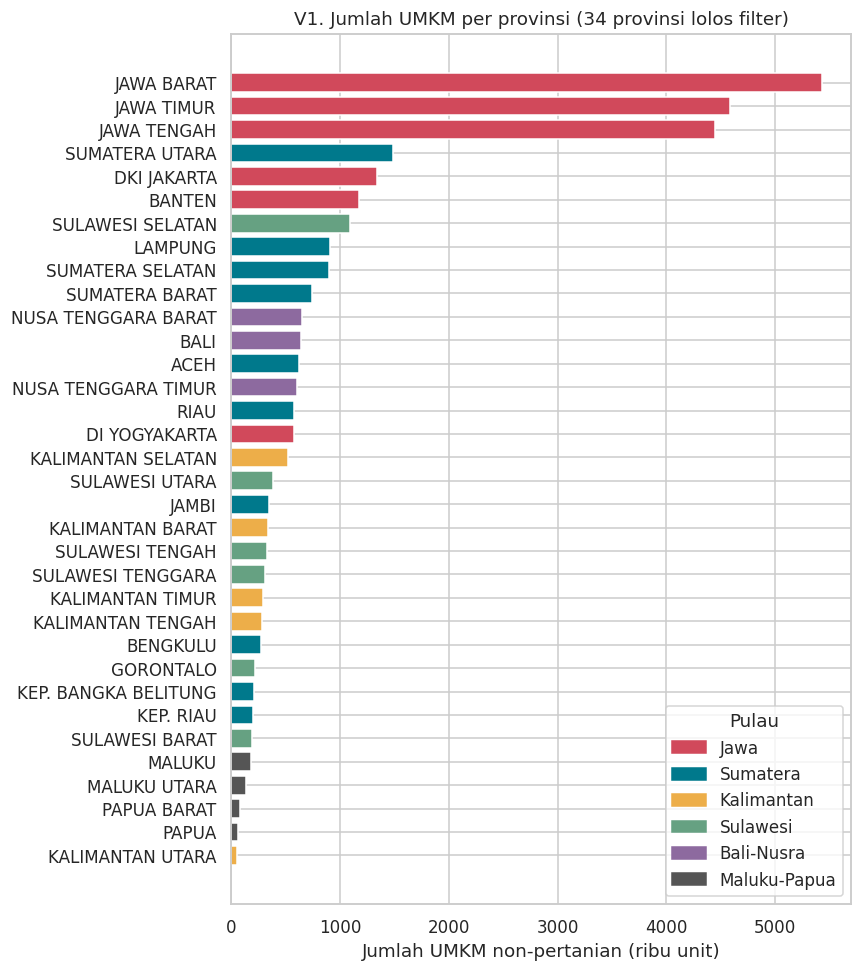

In [66]:
o = d.sort_values("umkm_total")
fig, ax = plt.subplots(figsize=(8, 9))
ax.barh(o["provinsi"], o["umkm_total"]/1e3, color=o["pulau"].map(pal))
ax.set_xlabel("Jumlah UMKM non-pertanian (ribu unit)")
ax.set_title("V1. Jumlah UMKM per provinsi (34 provinsi lolos filter)")
handles = [plt.Rectangle((0,0),1,1,color=c) for c in pal.values()]
ax.legend(handles, pal.keys(), loc="lower right", title="Pulau")
plt.tight_layout(); plt.show()

**Interpretasi bisnis V1.** Pasar UMKM sangat terkonsentrasi di Jawa: Jawa Barat, Jawa Timur, dan Jawa Tengah masing-masing 4,4–5,4 juta unit, jauh di atas provinsi nomor 4 (Sumatera Utara ±1,5 juta). Bagi SDR Skalar, volume leads terbesar secara absolut ada di Pulau Jawa, tetapi ukuran saja belum cukup — perlu dikombinasikan dengan kesiapan digital (V3, V7).

### Visual 2 — Univariate: bentuk sebaran (histogram) UMKM, mean vs median

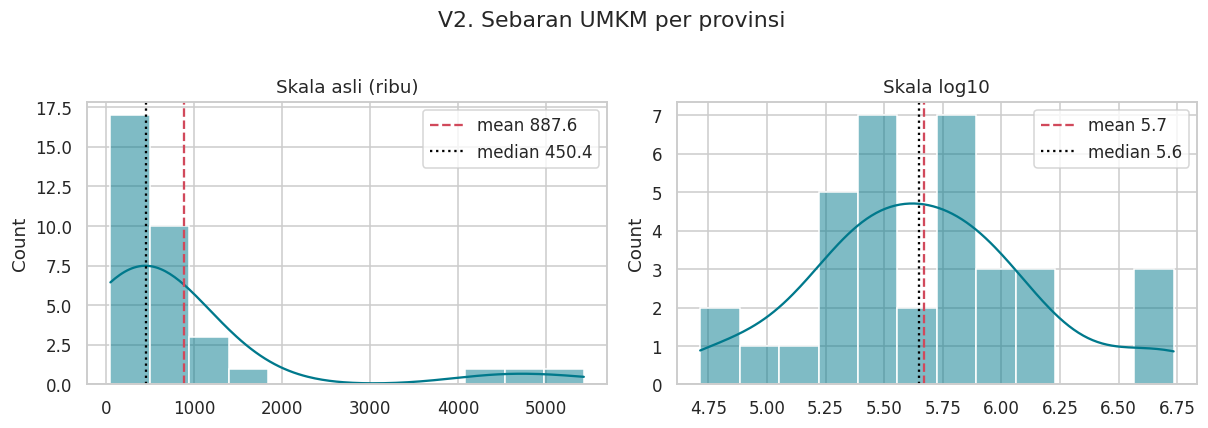

Skewness UMKM: raw = 2.70 | log = 0.34
Tiga provinsi terbesar menguasai 47.9% dari total UMKM di 34 provinsi.


In [67]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, col, ttl in [(axes[0], d["umkm_total"]/1e3, "Skala asli (ribu)"), (axes[1], np.log10(d["umkm_total"]), "Skala log10")]:
    sns.histplot(col, bins=12, kde=True, ax=ax, color="#00798c")
    ax.axvline(col.mean(), color="#d1495b", ls="--", label=f"mean {col.mean():,.1f}")
    ax.axvline(col.median(), color="black", ls=":", label=f"median {col.median():,.1f}")
    ax.set_title(ttl); ax.legend(); ax.set_xlabel("")
fig.suptitle("V2. Sebaran UMKM per provinsi", y=1.02)
plt.tight_layout(); plt.show()
print(f"Skewness UMKM: raw = {d['umkm_total'].skew():.2f} | log = {np.log1p(d['umkm_total']).skew():.2f}")
top3 = d.nlargest(3, "umkm_total")["umkm_total"].sum() / d["umkm_total"].sum()
print(f"Tiga provinsi terbesar menguasai {top3:.1%} dari total UMKM di 34 provinsi.")

**Interpretasi bisnis V2.** Sebaran UMKM sangat miring ke kanan (skewness ±2,7): mean (±888 ribu) hampir dua kali median (±450 ribu), jadi "rata-rata provinsi" menyesatkan. Tiga provinsi terbesar menguasai ±48% UMKM dari 34 provinsi. Setelah transformasi log skewness turun menjadi ±0,3 → alasan kami memakai **log1p sebelum Min-Max** agar provinsi kecil-menengah tidak semuanya menumpuk di dekat 0.

### Visual 3 — Bivariate: indikator kesiapan digital & aktivitas ekonomi vs jumlah UMKM

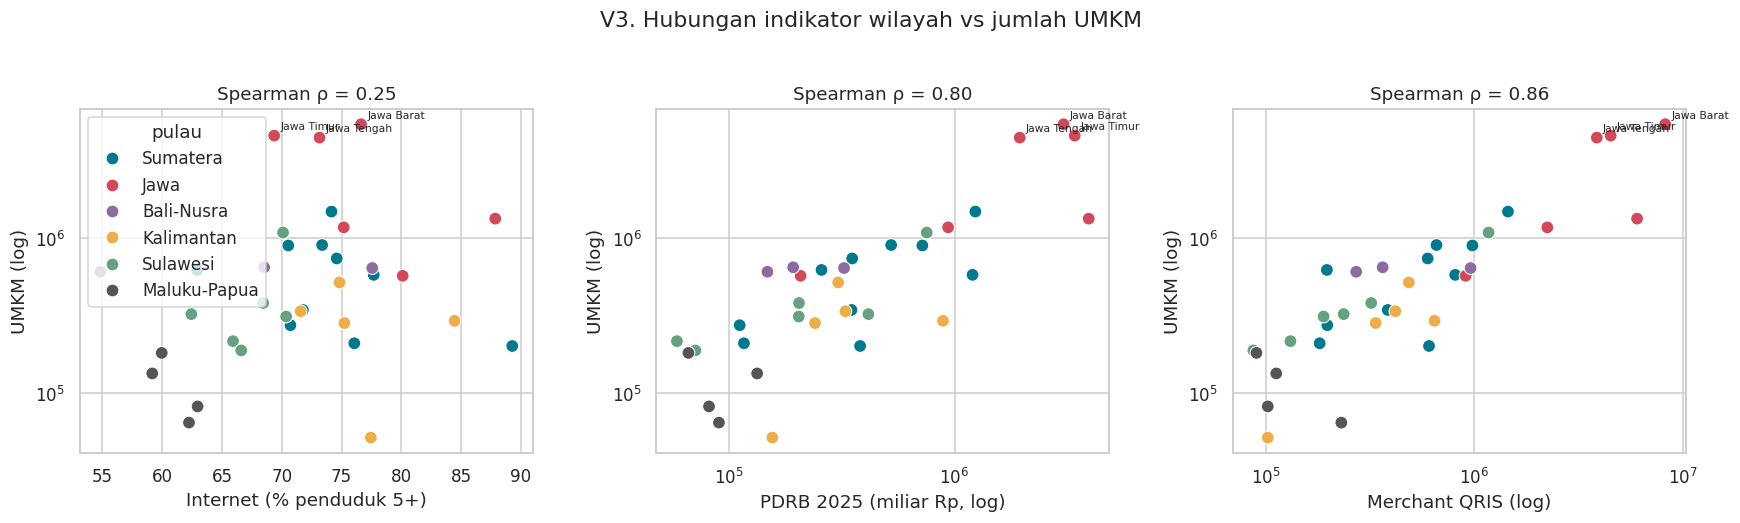

In [68]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
pairs = [("internet_total","Internet (% penduduk 5+)", False),
         ("pdrb","PDRB 2025 (miliar Rp, log)", True),
         ("qris_merchant","Merchant QRIS (log)", True)]
for ax, (x, lbl, lg) in zip(axes, pairs):
    sns.scatterplot(data=d, x=x, y="umkm_total", hue="pulau", palette=pal, s=70, ax=ax, legend=(x=="internet_total"))
    if lg: ax.set_xscale("log")
    ax.set_yscale("log")
    rho = d[[x,"umkm_total"]].corr(method="spearman").iloc[0,1]
    ax.set_title(f"Spearman ρ = {rho:.2f}"); ax.set_xlabel(lbl); ax.set_ylabel("UMKM (log)")
    for _, r in d.nlargest(3, "umkm_total").iterrows():
        ax.annotate(r["provinsi"].title(), (r[x], r["umkm_total"]), fontsize=7, xytext=(4,4), textcoords="offset points")
fig.suptitle("V3. Hubungan indikator wilayah vs jumlah UMKM", y=1.03)
plt.tight_layout(); plt.show()

**Interpretasi bisnis V3.** Jumlah UMKM berhubungan kuat dengan PDRB (ρ≈0,80) dan merchant QRIS (ρ≈0,86), tetapi **lemah dengan persentase internet (ρ≈0,25)**. Artinya provinsi dengan UMKM terbanyak tidak otomatis paling siap digital, dan sebaliknya (mis. Kep. Riau & Kaltim internet tinggi tetapi UMKM sedang). Konsekuensi: internet membawa informasi yang *berbeda* dari ukuran pasar, sehingga layak jadi komponen skor tersendiri. Catatan: korelasi ≠ sebab-akibat; hubungan UMKM–PDRB–QRIS sebagian besar mencerminkan ukuran provinsi.

### Visual 4 — Bivariate: adopsi QRIS relatif terhadap UMKM (rasio)

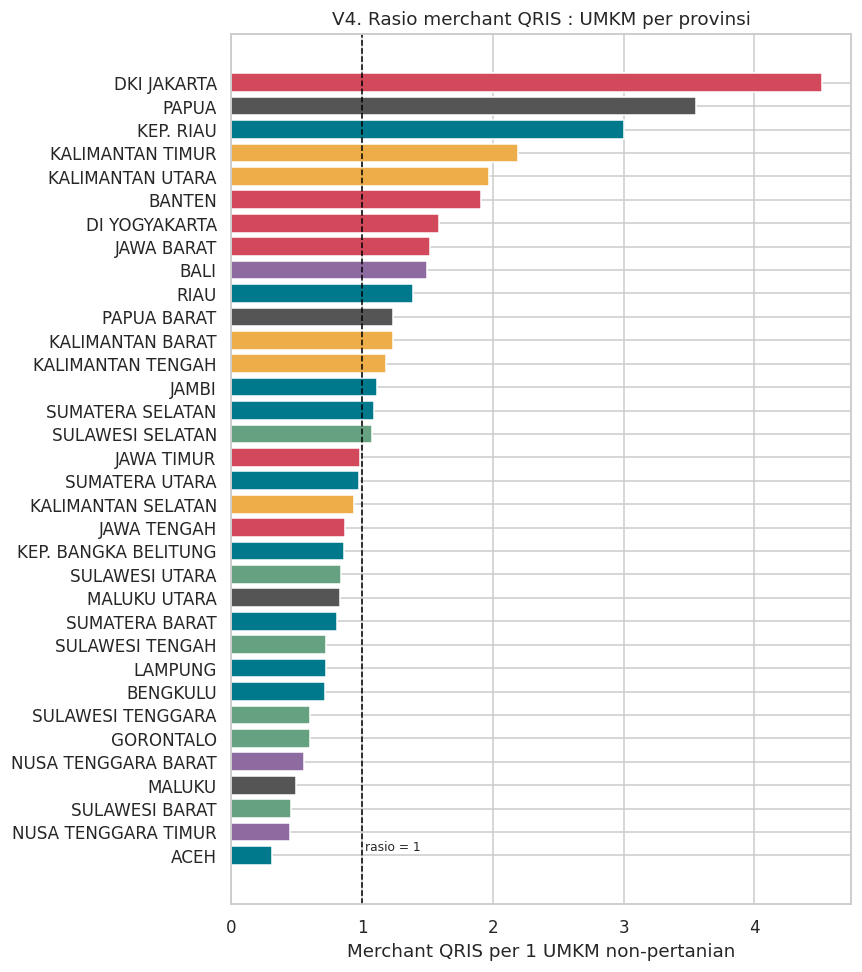

In [69]:
o = d.sort_values("qris_per_umkm")
fig, ax = plt.subplots(figsize=(8, 9))
ax.barh(o["provinsi"], o["qris_per_umkm"], color=o["pulau"].map(pal))
ax.axvline(1, color="black", ls="--", lw=1); ax.text(1.02, 0.2, "rasio = 1", fontsize=8)
ax.set_xlabel("Merchant QRIS per 1 UMKM non-pertanian")
ax.set_title("V4. Rasio merchant QRIS : UMKM per provinsi")
plt.tight_layout(); plt.show()

**Interpretasi bisnis V4.** Rasio QRIS/UMKM > 1 di 16 dari 34 provinsi (puncaknya DKI Jakarta ±4,5 dan Papua ±3,6). Ini **bukan** berarti satu UMKM punya beberapa merchant, melainkan QRIS mencakup seluruh merchant (termasuk pertanian, pedagang individu, non-UMKM) dan kemungkinan tercatat di lokasi kantor penyedia jasa/aggregator; untuk Papua juga kemungkinan mencakup provinsi pemekaran. Rasio rendah (Aceh ±0,31, NTT ±0,45, Sulawesi Barat ±0,46, Maluku ±0,49) menandai provinsi dengan UMKM banyak tetapi adopsi QRIS relatif rendah → **peluang edukasi**, tetapi juga risiko onboarding lebih sulit. Karena itu rasio ini dipakai untuk EDA saja, bukan untuk skor.

### Visual 5 — Univariate per kelompok: kesiapan digital per pulau & jurang urban–rural

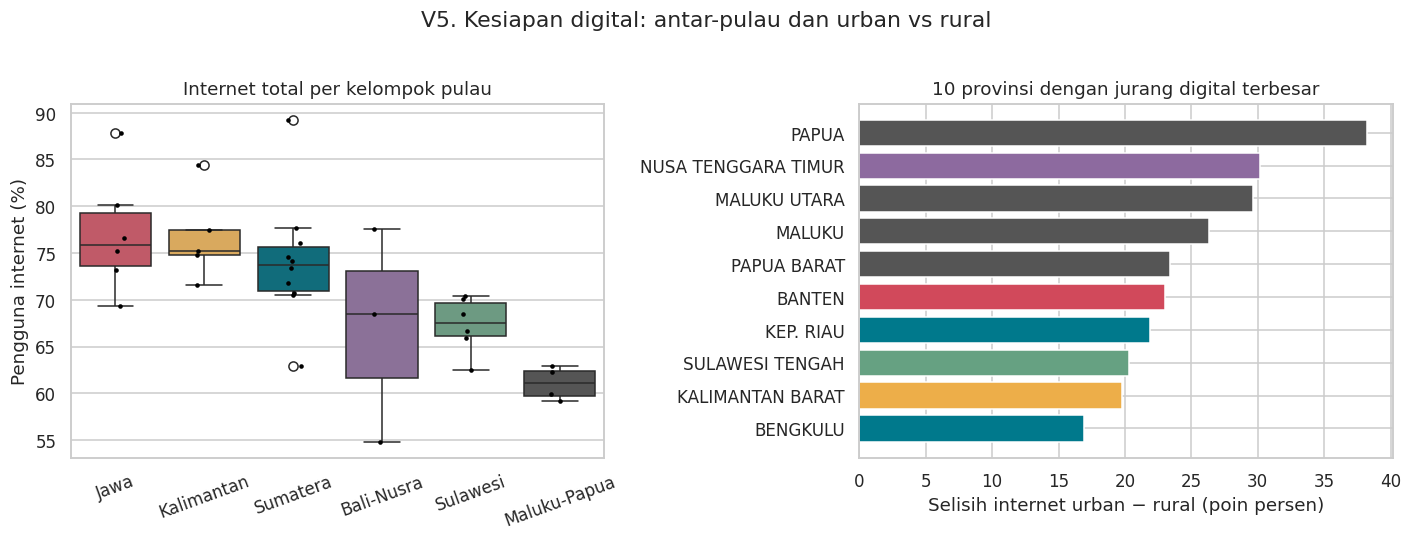

In [70]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
order = d.groupby("pulau")["internet_total"].median().sort_values(ascending=False).index
sns.boxplot(data=d, x="pulau", y="internet_total", hue="pulau", order=order, palette=pal, legend=False, ax=axes[0])
sns.stripplot(data=d, x="pulau", y="internet_total", order=order, color="black", size=3, ax=axes[0])
axes[0].set_xlabel(""); axes[0].set_ylabel("Pengguna internet (%)"); axes[0].set_title("Internet total per kelompok pulau")
axes[0].tick_params(axis="x", rotation=20)

g = d.dropna(subset=["gap_internet"]).sort_values("gap_internet", ascending=False).head(10).iloc[::-1]
axes[1].barh(g["provinsi"], g["gap_internet"], color=g["pulau"].map(pal))
axes[1].set_xlabel("Selisih internet urban − rural (poin persen)"); axes[1].set_title("10 provinsi dengan jurang digital terbesar")
fig.suptitle("V5. Kesiapan digital: antar-pulau dan urban vs rural", y=1.02)
plt.tight_layout(); plt.show()

**Interpretasi bisnis V5.** Median internet tertinggi di Jawa (±75,9%), Kalimantan (±75,2%), dan Sumatera (±73,8%); terendah Maluku-Papua (±61,1%). Jurang urban–rural terbesar ada di Papua (±38 poin), NTT (±30), Maluku Utara (±30), dan Maluku (±26): di wilayah ini calon klien di luar ibu kota cenderung sulit dijangkau secara digital. Untuk strategi sourcing: fokus awal di kota besar/urban, bukan seluruh provinsi.

### Visual 6 — Multivariate: matriks korelasi (heatmap)

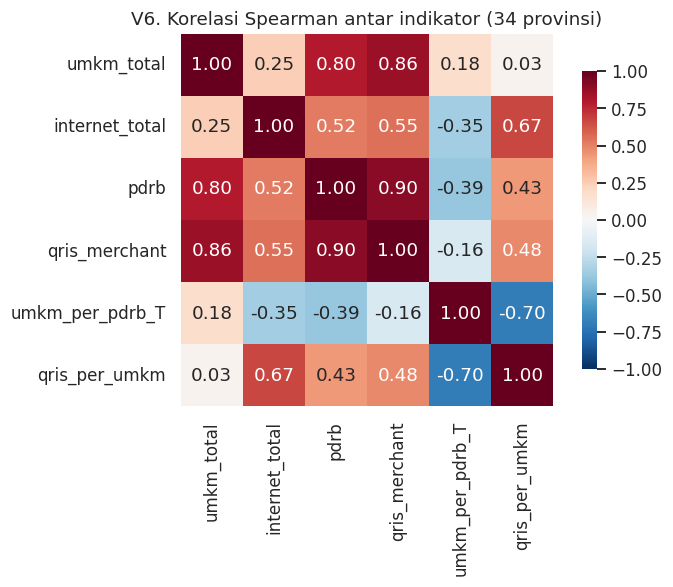

In [71]:
cols = ["umkm_total","internet_total","pdrb","qris_merchant","umkm_per_pdrb_T","qris_per_umkm"]
corr = d[cols].corr(method="spearman")
plt.figure(figsize=(7, 5.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, square=True, cbar_kws={"shrink":.8})
plt.title("V6. Korelasi Spearman antar indikator (34 provinsi)")
plt.tight_layout(); plt.show()

**Interpretasi bisnis V6.** Tiga indikator "ukuran" (UMKM, PDRB, QRIS) saling berkorelasi tinggi (ρ 0,80–0,86 dengan UMKM) → ada risiko **double-counting efek ukuran provinsi** bila ketiganya diberi bobot besar sekaligus (lihat justifikasi bobot PDRB yang sengaja diturunkan). Indikator internet relatif independen dari UMKM (ρ≈0,25). Yang paling perlu diwaspadai: `umkm_per_pdrb_T` berkorelasi **negatif** dengan internet (ρ≈−0,35) dan PDRB (ρ≈−0,39), yaitu UMKM paling "padat" justru di provinsi yang ekonominya kecil/kurang digital.

### Visual 7 — Multivariate: bubble chart (internet × PDRB × UMKM × pulau)

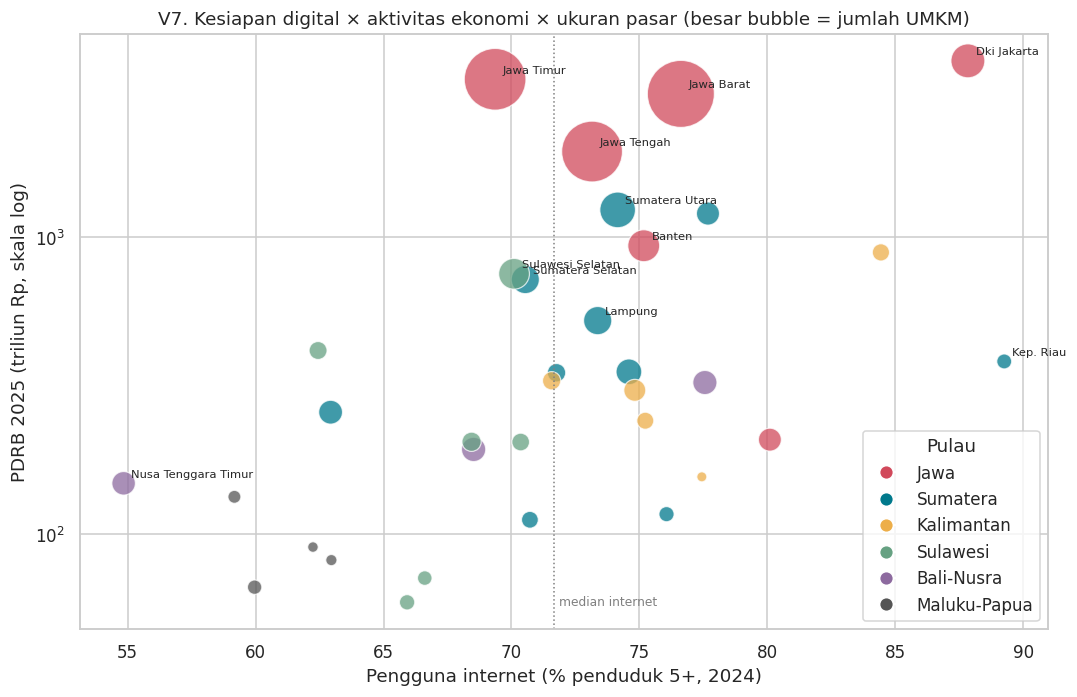

In [72]:
fig, ax = plt.subplots(figsize=(10, 6.5))
sc = ax.scatter(d["internet_total"], d["pdrb"]/1e3, s=d["umkm_total"]/1e3*0.35+25,
                c=d["pulau"].map(pal), alpha=.75, edgecolor="white", linewidth=.8)
ax.set_yscale("log")
ax.set_xlabel("Pengguna internet (% penduduk 5+, 2024)"); ax.set_ylabel("PDRB 2025 (triliun Rp, skala log)")
ax.set_title("V7. Kesiapan digital × aktivitas ekonomi × ukuran pasar (besar bubble = jumlah UMKM)")
for _, r in d.iterrows():
    if r["umkm_total"] > 800_000 or r["internet_total"] > 85 or r["internet_total"] < 55:
        ax.annotate(r["provinsi"].title(), (r["internet_total"], r["pdrb"]/1e3), fontsize=7.5, xytext=(5,4), textcoords="offset points")
ax.legend([plt.Line2D([0],[0],marker="o",color="w",markerfacecolor=c,markersize=9) for c in pal.values()], pal.keys(), title="Pulau", loc="lower right")
ax.axvline(d["internet_total"].median(), color="grey", ls=":", lw=1)
ax.text(d["internet_total"].median()+.2, ax.get_ylim()[0]*1.2, "median internet", fontsize=8, color="grey")
plt.tight_layout(); plt.show()

**Interpretasi bisnis V7.** Kuadran kanan-atas (internet di atas median, PDRB besar, bubble besar) berisi DKI Jakarta, Jawa Barat, Banten, dan Jawa Tengah — kandidat kuat prioritas (Jawa Timur UMKM-nya besar tetapi internetnya ±69%, sedikit di bawah median ±71,7%). Kep. Riau, Kaltim, dan DI Yogyakarta sangat siap digital tetapi pasarnya kecil-menengah (potensi *niche*). Provinsi Maluku-Papua dan NTT berada di kiri-bawah: pasar kecil dan kesiapan digital rendah → prioritas rendah. Sebanyak 11 dari 34 provinsi punya UMKM *dan* internet di atas median — ini pool awal yang layak dibandingkan di tahap skor.

### Ringkasan insight otomatis (dihitung dari data, bukan ditulis manual)

In [73]:
r = d[["umkm_total","internet_total","pdrb","qris_merchant"]].corr(method="spearman")
print(f"1. Korelasi UMKM–PDRB = {r.loc['umkm_total','pdrb']:.2f}; UMKM–QRIS = {r.loc['umkm_total','qris_merchant']:.2f}; UMKM–internet = {r.loc['umkm_total','internet_total']:.2f}")
print("2. Top 5 UMKM:", ", ".join(d.nlargest(5,'umkm_total')['provinsi'].str.title()))
print("3. Internet tertinggi:", ", ".join(d.nlargest(3,'internet_total')['provinsi'].str.title()),
      "| terendah:", ", ".join(d.nsmallest(3,'internet_total')['provinsi'].str.title()))
print("4. Rasio QRIS/UMKM tertinggi:", ", ".join(d.nlargest(3,'qris_per_umkm')['provinsi'].str.title()),
      "| terendah:", ", ".join(d.nsmallest(3,'qris_per_umkm')['provinsi'].str.title()))
print(f"5. Provinsi dengan UMKM > median DAN internet > median: {((d.umkm_total>d.umkm_total.median()) & (d.internet_total>d.internet_total.median())).sum()} dari {len(d)}")
print("   ->", ", ".join(d[(d.umkm_total>d.umkm_total.median()) & (d.internet_total>d.internet_total.median())]['provinsi'].str.title()))

1. Korelasi UMKM–PDRB = 0.80; UMKM–QRIS = 0.86; UMKM–internet = 0.25
2. Top 5 UMKM: Jawa Barat, Jawa Timur, Jawa Tengah, Sumatera Utara, Dki Jakarta
3. Internet tertinggi: Kep. Riau, Dki Jakarta, Kalimantan Timur | terendah: Nusa Tenggara Timur, Maluku Utara, Maluku
4. Rasio QRIS/UMKM tertinggi: Dki Jakarta, Papua, Kep. Riau | terendah: Aceh, Nusa Tenggara Timur, Sulawesi Barat
5. Provinsi dengan UMKM > median DAN internet > median: 11 dari 34
   -> Sumatera Utara, Sumatera Barat, Riau, Lampung, Dki Jakarta, Jawa Barat, Jawa Tengah, Di Yogyakarta, Banten, Bali, Kalimantan Selatan


---
# BAGIAN 4 — Rancangan Formulasi Bobot Indeks Prioritas (Berdasarkan Brief ICP Klay)

Format sesuai instruksi: **Komponen · Indikator publik · Arah (+/−) · Bobot (%) · Justifikasi bisnis**. Seluruh indikator sudah dinormalisasi 0–1 (Bagian 2.4) dengan arah **positif** (makin tinggi makin baik).

In [74]:
bobot = pd.DataFrame([
 ["Ukuran Pasar", "Jumlah UMKM non-pertanian (S1, log + Min-Max)", "+", 30,
  "ICP Bag.3: ukuran pasar = jumlah usaha mikro-kecil. Ini adalah ukuran 'pool leads' bagi SDR Skalar, sehingga diberi bobot terbesar."],
 ["Kepadatan Sektor Target", "PROXY: UMKM per Rp1 triliun PDRB (S1/S3, Min-Max)", "+", 10,
  "Data proporsi ritel/F&B/jasa tidak tersedia. Proxy hanya menangkap seberapa 'padat' UMKM terhadap ekonomi. PERHATIAN: proxy ini berkorelasi negatif dengan internet (ρ≈−0,35, lihat V6) sehingga lemah/bisa bias ke provinsi kurang digital; bobot sengaja kecil dan harus diganti bila ada data sektor (KBLI) di Final Project."],
 ["Kesiapan Digital", "% penduduk 5+ pengguna internet, total (S2, Min-Max)", "+", 20,
  "Klay adalah platform cloud: pemilik usaha & pelanggan harus bisa online. Internet rendah = onboarding & dashboard jarak jauh sulit."],
 ["Adopsi Pembayaran Digital", "Jumlah merchant QRIS (S4, log + Min-Max)", "+", 25,
  "ICP: pembayaran digital (QRIS) yang terintegrasi dengan pencatatan adalah pain point & fitur inti Klay; merchant yang sudah terima QRIS paling siap pindah ke POS."],
 ["Aktivitas Ekonomi", "PDRB ADHB 2025 (S3, log + Min-Max)", "+", 15,
  "ICP: PDRB sebagai proxy daya beli & volume transaksi harian. Bobot sedang karena sudah berkorelasi tinggi dengan Ukuran Pasar (menghindari double-counting)."],
], columns=["Komponen","Indikator publik yang dipakai","Arah (+/−)","Bobot (%)","Justifikasi bisnis (kaitan dengan ICP / produk Klay)"])

assert bobot["Bobot (%)"].sum() == 100, "Total bobot harus 100%"
assert bobot.shape[0] >= 4
display(bobot.style.set_properties(**{"text-align":"left","white-space":"pre-wrap"}).hide(axis="index"))
print("Total bobot =", bobot["Bobot (%)"].sum(), "%  |  Jumlah komponen =", bobot.shape[0])

Komponen,Indikator publik yang dipakai,Arah (+/−),Bobot (%),Justifikasi bisnis (kaitan dengan ICP / produk Klay)
Ukuran Pasar,"Jumlah UMKM non-pertanian (S1, log + Min-Max)",+,30,"ICP Bag.3: ukuran pasar = jumlah usaha mikro-kecil. Ini adalah ukuran 'pool leads' bagi SDR Skalar, sehingga diberi bobot terbesar."
Kepadatan Sektor Target,"PROXY: UMKM per Rp1 triliun PDRB (S1/S3, Min-Max)",+,10,"Data proporsi ritel/F&B/jasa tidak tersedia. Proxy hanya menangkap seberapa 'padat' UMKM terhadap ekonomi. PERHATIAN: proxy ini berkorelasi negatif dengan internet (ρ≈−0,35, lihat V6) sehingga lemah/bisa bias ke provinsi kurang digital; bobot sengaja kecil dan harus diganti bila ada data sektor (KBLI) di Final Project."
Kesiapan Digital,"% penduduk 5+ pengguna internet, total (S2, Min-Max)",+,20,Klay adalah platform cloud: pemilik usaha & pelanggan harus bisa online. Internet rendah = onboarding & dashboard jarak jauh sulit.
Adopsi Pembayaran Digital,"Jumlah merchant QRIS (S4, log + Min-Max)",+,25,ICP: pembayaran digital (QRIS) yang terintegrasi dengan pencatatan adalah pain point & fitur inti Klay; merchant yang sudah terima QRIS paling siap pindah ke POS.
Aktivitas Ekonomi,"PDRB ADHB 2025 (S3, log + Min-Max)",+,15,ICP: PDRB sebagai proxy daya beli & volume transaksi harian. Bobot sedang karena sudah berkorelasi tinggi dengan Ukuran Pasar (menghindari double-counting).


Total bobot = 100 %  |  Jumlah komponen = 5


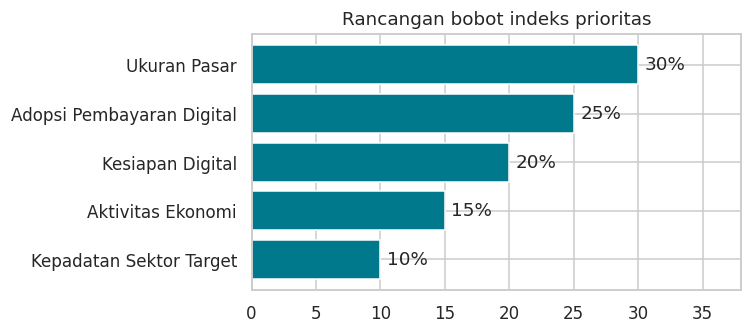

In [75]:
# Visual ringkas bobot
plt.figure(figsize=(7,3.2))
b = bobot.sort_values("Bobot (%)")
plt.barh(b["Komponen"], b["Bobot (%)"], color="#00798c")
for i, v in enumerate(b["Bobot (%)"]): plt.text(v+.5, i, f"{v}%", va="center")
plt.xlim(0, 38); plt.title("Rancangan bobot indeks prioritas"); plt.tight_layout(); plt.show()

### Rumus indeks

$$\text{Skor}_{p} = 0{,}30\,UMKM^{n}_p + 0{,}10\,Kepadatan^{n}_p + 0{,}20\,Internet^{n}_p + 0{,}25\,QRIS^{n}_p + 0{,}15\,PDRB^{n}_p$$

dengan $x^{n}$ = nilai ternormalisasi Min-Max (0–1). Hubungan dengan K-Means (Final Project): K-Means pada 5 fitur ternormalisasi di `df_norm` memberi **tipe wilayah**, sedangkan skor ini memberi **urutan prioritas** di dalam/antar tipe.

### Keterbatasan data
1. **Tidak ada dimensi sektor** → tidak bisa menyaring ritel/F&B/jasa; "segmen" (sektor × wilayah) baru bisa dibentuk di level wilayah saja. Mitigasi: proxy kepadatan, bobot kecil; langkah lanjut: Sensus Ekonomi / data KBLI per provinsi.
2. **Level provinsi**, bukan kab/kota → provinsi besar (Jawa Barat) menyembunyikan variasi antar kota.
3. **Beda tahun**: UMKM 2025, internet 2024, QRIS Q1-2025, PDRB 2025 (angka sangat sementara).
4. **Multikolinearitas**: UMKM, PDRB, QRIS saling berkorelasi tinggi (lihat V6) → efek "ukuran provinsi" bisa terhitung berulang; perlu dicek di Uji Sensitivitas.
5. **QRIS** mencakup seluruh merchant (rasio QRIS/UMKM > 1 di banyak provinsi) dan 4 provinsi Papua pemekaran tidak terpisah.
6. Nilai UMKM dibaca dari grafik dan QRIS dibulatkan → ada galat pembulatan kecil.
7. **4 provinsi tereliminasi** (Papua Barat Daya, Papua Pegunungan, Papua Tengah, Papua Selatan) → analisis berlaku untuk 34 provinsi.

### Langkah berikutnya (Final Project)
K-Means (Elbow/Silhouette) → hitung skor & Top 5 → uji sensitivitas bobot & ambang eliminasi → analisis robots.txt/ToS → slide presentasi.